# 04 — Motor prescritivo e backtest

Acopla a previsão da LSTM (`src/models/predict.py`) ao motor de **programação dinâmica estocástica** (`src/decision/engine.py`) e compara, no **teste cego** (jul/2024 em diante), com os benchmarks de comercialização (`src/decision/benchmarks.py`).

**Formulação:** parada ótima mensal em até 6 meses. Estado = (mês, preço); transição = cadeia de Markov sobre uma grade de log-preços, com deriva da trajetória prevista pela LSTM e variância da incerteza residual do modelo na validação. Ações: **VENDER** no físico, **ARMAZENAR** descoberto (armazenagem + quebra + custo de oportunidade) ou **ARMAZENAR+HEDGE** — vender futuro do vencimento *m* e armazenar até *m*, recebendo o **preço travado** `F_m·(1 + base_m) − custo operacional` (metodologia do módulo 5 AgroSafety), sujeito só ao **risco de base**. Aversão a risco opcional via certeza-equivalente `E − λ·DP`.

**Hedge (`src/decision/hedge.py`):** instrumento = Coffee C (ICE NY) × PTAX, proxy do ICF/B3. A base em R$ escala com o preço, mas em % do futuro é estável (≈ −20%), então usa-se base percentual sazonal por mês e risco de base = desvio da variação da base em 21/63/126 dias — ambos estimados **só no treino**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
plt.rcParams['figure.figsize'] = (12, 4)

from src.models.dataset import TARGET
from src.models.predict import forecast, load_artifacts, residual_sigma
from src.decision.engine import Custos, recomendar, grafo_decisoes, K_MAX
from src.decision.backtest import rodar_backtest, resumo

model, scaler, df = load_artifacts()
sigma = residual_sigma()
price = df[TARGET]
print('σ residual (validação):', {h: round(s, 3) for h, s in sigma.items()})

σ residual (validação): {21: 0.089, 63: 0.153, 126: 0.118}


## 1. Parâmetros econômicos

Valores padrão em R$/saca; **substituir pelos dados CONAB (COE) e da cooperativa (armazenagem)** antes da versão final.

In [2]:
custos = Custos(armazenagem_saca_mes=2.5, quebra_pct_mes=0.002, coe_saca=700.0,
                taxa_desconto_aa=0.10, aversao_risco=0.0)  # caso base do anexo: 10 % a.a.; a Selic vigente entra só na sensibilidade (bloco A1)
custos

Custos(armazenagem_saca_mes=2.5, quebra_pct_mes=0.002, coe_saca=700.0, taxa_desconto_aa=0.1, aversao_risco=0.0, custo_op_b3_saca=10.0, permitir_hedge=True, margem_min_coe=None)

## 1b. Curva de futuros e base

Contratos ativos da ICE (`data/raw/ice_curve.csv`, acumulado a cada coleta) convertidos para R$/saca. A base histórica em % do futuro (spot CEPEA − ICE em R$) define o preço travado por vencimento.

base % sazonal (treino, 2015-01-01 a 2022-06-30): {1: '-19.7%', 2: '-17.9%', 3: '-18.9%', 4: '-19.6%', 5: '-20.0%', 6: '-20.1%', 7: '-21.6%', 8: '-21.4%', 9: '-22.5%', 10: '-22.3%', 11: '-21.1%', 12: '-20.2%'}
risco de base (pp) por horizonte: {21: '2.6%', 63: '3.6%', 126: '5.0%'}
base hoje: -25.8%  |  spot R$ 1748  |  1º vencimento R$ 2357


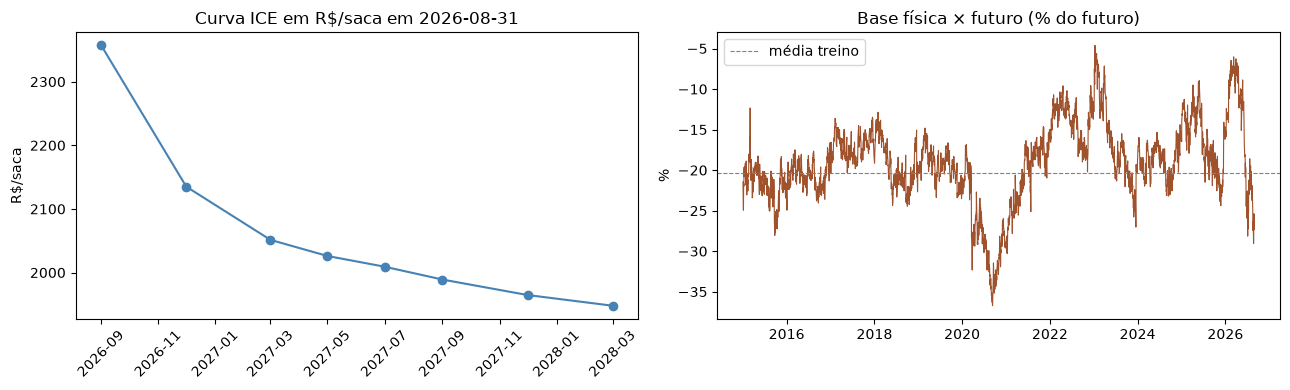

In [3]:
from src.decision.hedge import base_stats, curva_brl, futuro_por_mes, base_por_mes, risco_base_pct
st = base_stats()
data = df.index[-1]
ptax = float(df['ptax_venda'].loc[data])
curva = curva_brl(data, ptax)
print(f'base % sazonal (treino, {st["desde"]} a {st["ate"]}):', {m: f'{v:+.1%}' for m, v in st['base_pct_por_mes'].items()})
print('risco de base (pp) por horizonte:', {h: f'{v:.1%}' for h, v in st['risco_base_pct_por_h'].items()})
print(f'base hoje: {df["base_fisico_futuro_pct"].loc[data]:+.1%}  |  spot R$ {df[TARGET].loc[data]:.0f}  |  1º vencimento R$ {df["ice_arabica_brl_sc"].loc[data]:.0f}')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(curva.index, curva.values, 'o-', color='steelblue'); axes[0].set_title(f'Curva ICE em R$/saca em {data.date()}'); axes[0].set_ylabel('R$/saca'); axes[0].tick_params(axis='x', rotation=45)
b = df['base_fisico_futuro_pct'].loc['2015':] * 100
axes[1].plot(b.index, b.values, color='sienna', lw=0.8); axes[1].axhline(st['base_pct_media']*100, color='gray', ls='--', lw=0.8, label='média treino')
axes[1].set_title('Base física × futuro (% do futuro)'); axes[1].set_ylabel('%'); axes[1].legend()
plt.tight_layout()

## 2. Recomendação para a última data disponível

Compara três alternativas no preço de hoje: vender, armazenar descoberto (LSTM) e armazenar com hedge (curva + base esperada).

In [4]:
yhat = forecast(data, df, model, scaler)
p_hoje = float(price.loc[data])
F = futuro_por_mes(data, ptax, float(df['ice_arabica_brl_sc'].loc[data]), K_MAX)
bexp = base_por_mes(data, K_MAX, stats=st)
rb = np.array([risco_base_pct(j * 21, st) for j in range(K_MAX + 1)])
rec = recomendar(p_hoje, yhat, sigma, custos, futuros=F, base_pct=bexp, risco_base_pct=rb)
print(data.date(), '| ŷ:', {h: f'{v:+.1%}' for h, v in yhat.items()})
print(rec)
pd.DataFrame({'preço previsto (LSTM)': rec.trajetoria_prevista.round(0),
              'futuro R$/sc': rec.curva_futuro.round(0),
              'base esperada %': (rec.base_esperada * 100).round(1),
              'preço travado': (rec.curva_futuro * (1 + rec.base_esperada) - custos.custo_op_b3_saca).round(0),
              'gatilho de venda': rec.gatilhos.round(0),
              'P(vender no mês)': rec.dist_mes_venda.round(2)})

2026-08-31 | ŷ: {21: '+4.3%', 63: '+8.1%', 126: '+10.6%'}
ARMAZENAR | preço hoje R$ 1748/sc | vender R$ 1748 × armazenar R$ 1855 × hedge→1m R$ 1796 (trava R$ 1816) (+6.1% vs vender) | mês de venda esperado 3.0 | margem sobre COE +150%


,preço previsto (LSTM),futuro R$/sc,base esperada %,preço travado,gatilho de venda,P(vender no mês)
0,1748.0,2357.0,-21.4,1842.0,NaN,0.0
1,1826.0,2357.0,-22.5,1816.0,3181.0,0.0
2,1861.0,2135.0,-22.3,1649.0,3069.0,0.0
3,1897.0,2135.0,-21.1,1674.0,853.0,1.0
4,1912.0,2135.0,-20.2,1694.0,853.0,0.0
5,1928.0,2051.0,-19.7,1638.0,853.0,0.0
6,1943.0,2051.0,-17.9,1674.0,853.0,0.0


In [5]:
# sensibilidade da recomendação de hoje à aversão a risco
for lam in [0.0, 0.25, 0.5, 1.0]:
    r = recomendar(p_hoje, yhat, sigma, Custos(**{**custos.__dict__, 'aversao_risco': lam}), futuros=F, base_pct=bexp, risco_base_pct=rb)
    print(f'lambda={lam:<4}', r)

lambda=0.0  ARMAZENAR | preço hoje R$ 1748/sc | vender R$ 1748 × armazenar R$ 1855 × hedge→1m R$ 1796 (trava R$ 1816) (+6.1% vs vender) | mês de venda esperado 3.0 | margem sobre COE +150%
lambda=0.25 ARMAZENAR+HEDGE | preço hoje R$ 1748/sc | vender R$ 1748 × armazenar R$ 1772 × hedge→1m R$ 1781 (trava R$ 1816) (+1.9% vs vender) | mês de venda esperado 1.0 | margem sobre COE +150%
lambda=0.5  ARMAZENAR+HEDGE | preço hoje R$ 1748/sc | vender R$ 1748 × armazenar R$ 1732 × hedge→1m R$ 1766 (trava R$ 1816) (+1.0% vs vender) | mês de venda esperado 1.0 | margem sobre COE +150%
lambda=1.0  VENDER | preço hoje R$ 1748/sc | vender R$ 1748 × armazenar R$ 1651 × hedge→1m R$ 1736 (trava R$ 1816) (-0.7% vs vender) | mês de venda esperado 0.0 | margem sobre COE +150%


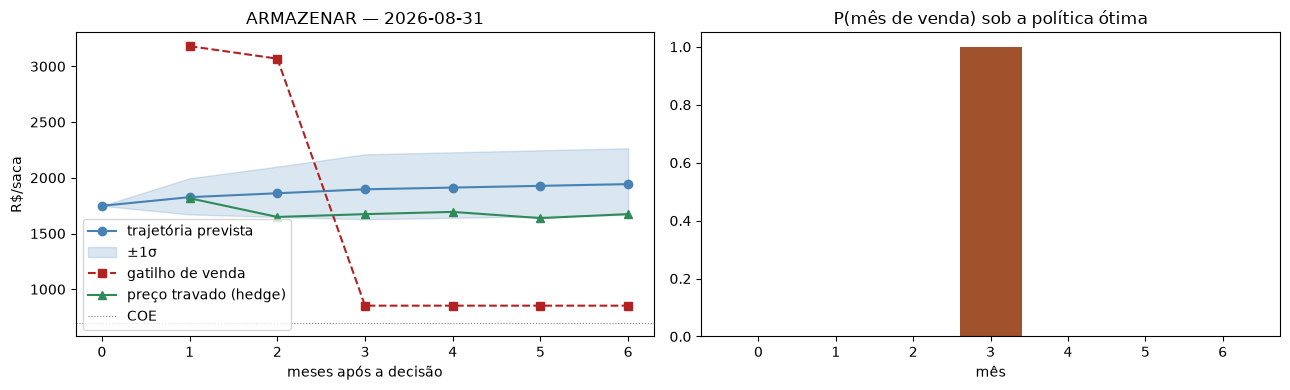

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
meses = np.arange(K_MAX + 1)
mu = np.log(rec.trajetoria_prevista / p_hoje)
sd = np.sqrt(np.maximum.accumulate(np.interp(meses * 21, [0, 21, 63, 126], [0, *sigma.values()]) ** 2))
ax = axes[0]
ax.plot(meses, rec.trajetoria_prevista, 'o-', color='steelblue', label='trajetória prevista')
ax.fill_between(meses, p_hoje * np.exp(mu - sd), p_hoje * np.exp(mu + sd), alpha=0.2, color='steelblue', label='±1σ')
ax.plot(meses, rec.gatilhos, 's--', color='firebrick', label='gatilho de venda')
ax.plot(meses[1:], (rec.curva_futuro * (1 + rec.base_esperada) - custos.custo_op_b3_saca).iloc[1:], '^-', color='seagreen', label='preço travado (hedge)')
ax.axhline(custos.coe_saca, color='gray', lw=0.8, ls=':', label='COE')
ax.set_xlabel('meses após a decisão'); ax.set_ylabel('R$/saca'); ax.legend(); ax.set_title(f'{rec.acao} — {data.date()}')
axes[1].bar(meses, rec.dist_mes_venda, color='sienna'); axes[1].set_title('P(mês de venda) sob a política ótima'); axes[1].set_xlabel('mês')
plt.tight_layout()

## 3. Grafo temporal de decisões

Árvore de cenários enxuta (quantis 10/50/90 por mês) com a ação ótima em cada nó.

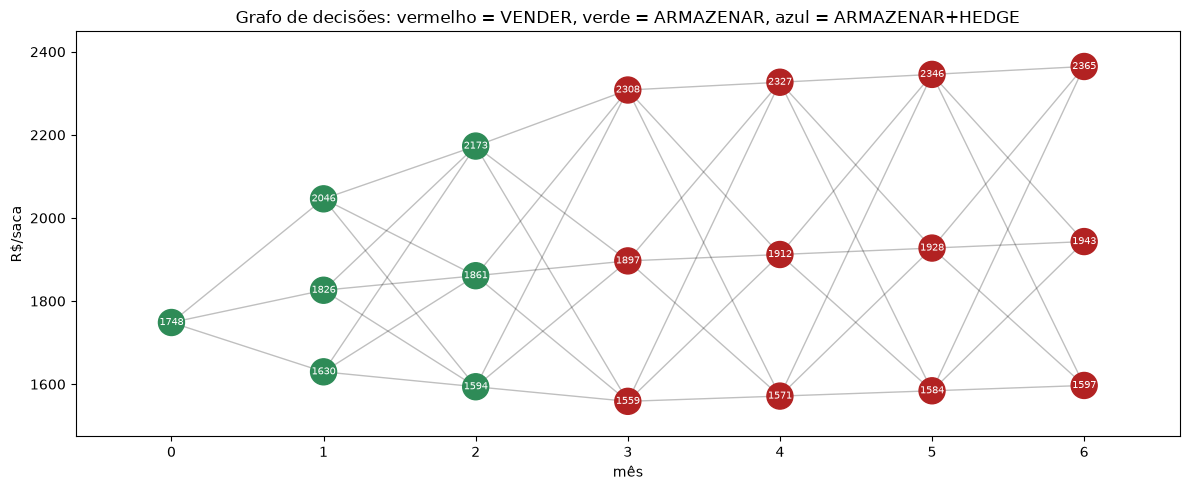

In [7]:
import networkx as nx

G = grafo_decisoes(rec, yhat, sigma)
pos = {n: (d['mes'], d['preco']) for n, d in G.nodes(data=True)}
cores = [{'VENDER': 'firebrick', 'ARMAZENAR': 'seagreen', 'ARMAZENAR+HEDGE': 'steelblue'}[d['acao']] for _, d in G.nodes(data=True)]
fig, ax = plt.subplots(figsize=(12, 5))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.25, arrows=False)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=cores, node_size=350)
nx.draw_networkx_labels(G, pos, {n: f"{d['preco']:.0f}" for n, d in G.nodes(data=True)}, font_size=7, font_color='white', ax=ax)
ax.set_xlabel('mês'); ax.set_ylabel('R$/saca'); ax.set_title('Grafo de decisões: vermelho = VENDER, verde = ARMAZENAR, azul = ARMAZENAR+HEDGE')
ax.set_axis_on(); ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
plt.tight_layout()

## 4. Backtest cego no teste (jul/2024 →)

Decisões mensais; a política LSTM+DP é reavaliada a cada mês com a previsão daquela data. Todas as estratégias usam a mesma contabilidade de custos.

- `venda_imediata`, `venda_parcelada` (1/7 por mês), `media_movel_3m`, `meta_margem_coe` (COE·1,3)
- `hedge_ate_o_fim`: armazena 6 meses com hedge rolado no 1º vencimento desde o dia da decisão
- `lstm_dp_sem_hedge` (só vender/armazenar) e `lstm_dp` (com a ação de hedge)
- `oraculo`: melhor mês conhecendo o futuro (limite superior)

**Limitação:** para datas passadas não há curva por vencimento (Yahoo descarta contratos vencidos), então a decisão de hedge no backtest usa curva plana e o resultado realizado é o do hedge rolado (rolagens embutidas na série contínua KC=F). A curva real passa a ser acumulada em `ice_curve.csv` a partir de set/2026.

In [8]:
bt = rodar_backtest(custos)
bt.to_csv(ROOT / 'reports' / 'backtest_teste.csv')
resumo(bt)

,receita_media_R$/sc,ganho_vs_imediata_%,vence_imediata_%,captura_oraculo_%,desvio_padrao,pior_caso_R$/sc
venda_imediata,2028.44,0.00,0.0,87.00,406.43,1361.92
venda_parcelada,2001.44,2.06,45.0,85.80,197.76,1593.64
media_movel_3m,1982.37,-1.57,10.0,84.78,450.97,1288.72
meta_margem_coe,2028.44,0.00,0.0,87.00,406.43,1361.92
hedge_ate_o_fim,1913.57,-6.07,20.0,82.11,457.65,1166.58
lstm_dp_sem_hedge,2186.28,10.17,35.0,93.73,269.01,1361.92
lstm_dp,2186.28,10.17,35.0,93.73,269.01,1361.92
oraculo,2331.63,19.44,60.0,100.00,164.39,1971.48


mês de venda da LSTM+DP: {0: 12, 1: 3, 2: 2, 3: 2, 4: 1}
ação inicial da LSTM+DP: {'VENDER': 12, 'ARMAZENAR': 8}


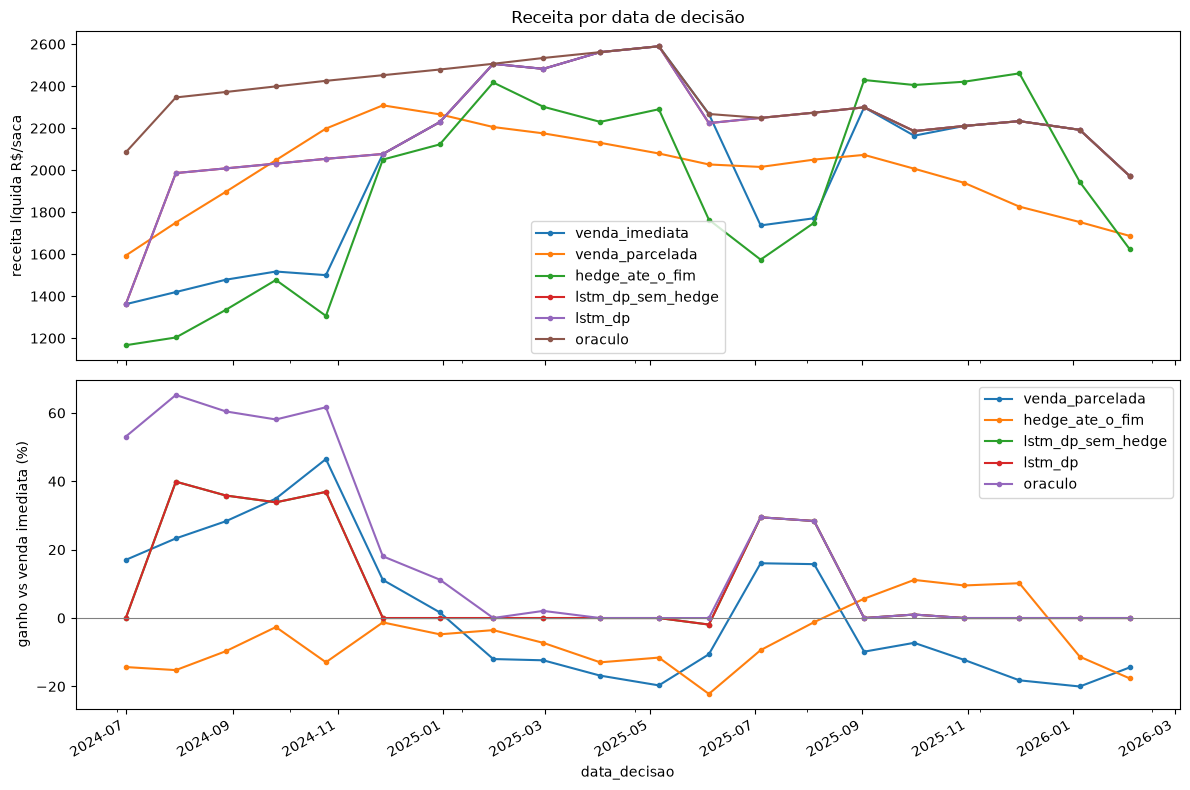

In [9]:
estrategias = ['venda_imediata', 'venda_parcelada', 'hedge_ate_o_fim', 'lstm_dp_sem_hedge', 'lstm_dp', 'oraculo']
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
bt[estrategias].plot(ax=axes[0], marker='o', ms=3); axes[0].set_ylabel('receita líquida R$/saca'); axes[0].set_title('Receita por data de decisão')
(bt[estrategias].div(bt['venda_imediata'], axis=0) - 1).mul(100).drop(columns='venda_imediata').plot(ax=axes[1], marker='o', ms=3)
axes[1].axhline(0, color='gray', lw=0.8); axes[1].set_ylabel('ganho vs venda imediata (%)')
plt.tight_layout()
print('mês de venda da LSTM+DP:', bt['lstm_dp_mes_venda'].value_counts().sort_index().to_dict())
print('ação inicial da LSTM+DP:', bt['lstm_dp_acao'].value_counts().to_dict())

## 5. Sensibilidade à aversão a risco e aos custos

In [10]:
linhas = []
for lam in [0.0, 0.25, 0.5, 1.0]:
    for arm in [1.5, 2.5, 5.0]:
        c = Custos(armazenagem_saca_mes=arm, coe_saca=custos.coe_saca, taxa_desconto_aa=custos.taxa_desconto_aa, aversao_risco=lam)
        r = resumo(rodar_backtest(c)).loc['lstm_dp']
        linhas.append({'λ': lam, 'armazenagem': arm, **r.to_dict()})
pd.DataFrame(linhas).set_index(['λ', 'armazenagem']).round(2)

receita_media_R$/sc  ganho_vs_imediata_%  vence_imediata_%  \
λ    armazenagem                                                               
0.00 1.5                      2187.13                10.22              35.0   
     2.5                      2186.28                10.17              35.0   
     5.0                      2184.17                10.04              35.0   
0.25 1.5                      2188.00                10.26              30.0   
     2.5                      2187.35                10.22              30.0   
     5.0                      2185.74                10.11              30.0   
0.50 1.5                      2030.31                 0.12              10.0   
     2.5                      2029.50                 0.07               5.0   
     5.0                      2029.38                 0.06               5.0   
1.00 1.5                      2028.44                 0.00               0.0   
     2.5                      2028.44                 0.00               0.0   
     5.0                      2028.44                 0.00               0.0   

                  captura_oraculo_%  desvio_padrao  pior_caso_R$/sc  
λ    armazenagem                                                     
0.00 1.5                      93.69         268.73          1361.92  
     2.5                      93.73         269.01          1361.92  
     5.0                      93.79         269.73          1361.92  
0.25 1.5                      93.72         269.25          1361.92  
     2.5                      93.78         269.56          1361.92  
     5.0                      93.85         270.34          1361.92  
0.50 1.5                      87.01         404.31          1361.92  
     2.5                      87.04         404.94          1361.92  
     5.0                      87.16         405.11          1361.92  
1.00 1.5                      86.93         406.43          1361.92  
     2.5                      87.00         406.43          1361.92  
     5.0                      87.12         406.43          1361.92

## Leitura dos resultados

- A comparação relevante é **ganho vs venda imediata** e **captura do oráculo**: o motor só é útil se superar a venda imediata com dispersão aceitável.
- `meta_margem_coe` coincide com a venda imediata no período de teste porque o preço já estava muito acima de COE·1,3 em todas as datas — com o COE real da CONAB o benchmark passa a discriminar.
- O ganho do motor depende diretamente da qualidade direcional da LSTM (notebook 03). **A previsão implícita na curva de futuros + base sazonal vence a LSTM em 21 e 63 dias** (`rmse_curva` < `rmse_ret`), o que indica que a LSTM deve passar a prever o *excedente* sobre a curva (ou receber o retorno implícito como feature).
- Com curva plana (backtest) o hedge nunca supera a venda imediata: sem carry, travar só compensa quando a base está anormalmente fraca em relação à média sazonal. Na data atual é exatamente esse o caso (base ≈ −26% vs −21% sazonal), e o hedge de 1 mês trava acima do spot.
- `hedge_ate_o_fim` perde no período porque o mercado esteve em backwardation: rolar a posição vendida custa o spread entre vencimentos.